# 一维 SOFI 演示：慢速闪烁 × 二阶累积量（0 时滞 vs 1 时滞）

**目标**：在 1D 条件下，两个发射体（PSF 宽度与像素尺寸相当、间距 ~2.1σ 在衍射极限附近、原始不可分辨）如何通过 **SOFI（超分辨光学涨落成像）** 的二阶累积量把有效 PSF 宽度收窄（~√2），从而把原本不可分辨的双发射体分开。

**四个对照组合**：

| 闪烁 | 二阶累积量 | 预期结果 |
|---|---|---|
| 慢速闪烁 | 0 时滞 `⟨δI²⟩` | `PSF²`（收窄 √2）＋ 散粒噪声基底（形状≈`PSF`，不窄） |
| 慢速闪烁 | 1 时滞 `⟨δI(t)δI(t+1)⟩` | `PSF²`（收窄 √2），散粒噪声被**自动消除** |
| 无闪烁（常亮） | 0 时滞 | 只有散粒噪声 = 均值 ≈ 原始 `PSF`（**不变窄**） |
| 无闪烁（常亮） | 1 时滞 | ≈ 0（无时间相关性，无信号） |

**关键物理**：
- 每个发射体独立随机闪烁（两态马尔可夫，on/off 状态持续多个帧 = “慢速”闪烁，产生强时间相关性）。
- 光子数严格按 **Poisson** 统计抽取，亮度由 `BRIGHTNESS`（on 时峰值光子数/帧）一个参数控制。
- 0 时滞累积量 = 闪烁方差项（∝`PSF²`）＋ 散粒噪声项（∝均值≈`PSF`）；1 时滞累积量只含闪烁协方差项（∝`PSF²`）。

> 与本仓库 2D 实现的对应关系：`smlm.imgprocess.core` 里的 `cumulant_from_deltas` / `xc_cumulant` / `entromap`，以及 `smlm.imgprocess.sofi` 里的 `CumulantSofit` / `RiedSofit`。这里用最直白的 1D 手写版本以便教学。

## ⚙️ 参数区

所有可调参数（发射体位置、PSF 宽度、亮度、背景、帧数、闪烁速率、随机种子等）都集中在下面这个代码格里。改完参数后，从上到下 **Run All** 即可复现全部结果。

In [51]:
# =====================================================================
# ⚙️ 参数区 —— 所有可调参数集中在这里，改完从上到下 Run All 即可
# =====================================================================
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# matplotlib 中文字体（Windows），避免中文显示为方块
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

# ---------------- 1) 几何 / 光学 ----------------
N_PIX    = 64        # 1D 像素数
PIXEL_NM = 106.7     # 像素尺寸（nm / pixel）
SIGMA_PX = 1.2       # PSF σ（像素）—— 与像素尺寸相当（欠采样 PSF）
X1       = 25.0      # 发射体 1 位置（像素）
SEP_PX   = 2.8      # 两发射体间距（像素）—— ~2.1σ，原始均值不可分辨
X2       = X1 + SEP_PX   # 发射体 2 位置（像素，由 X1 + SEP_PX 自动算出）

# ---------------- 2) 亮度 / 光子统计 ----------------
BRIGHTNESS = 400.0   # 亮度：on 时峰值光子数/帧（唯一亮度参数，控制 Poisson 速率）
BG         = 0.0     # 背景光子 / 像素 / 帧（ECL 零背景）

# ---------------- 3) 采集 / 随机性 ----------------
N_FRAMES = 1000      # 帧数（越大累积量估计越稳、耗时略增）
SEED     = 42        # 随机种子（固定以便复现）

# ---------------- 4) 慢速闪烁（两态马尔可夫，每帧转移概率） ----------------
# 对称速率 → 两发射体 duty≈0.5、闪烁方差最大且统计量接近，双峰对称可分辨
K_ON_OFF = 0.15      # on→off，平均 on 约 6.7 帧
K_OFF_ON = 0.15      # off→on，平均 off 约 6.7 帧

In [52]:
def gauss_1d(x, x0, sigma):
    """峰归一化高斯 PSF。"""
    return np.exp(-0.5 * ((x - x0) / sigma) ** 2)


def markov_blink(n, k_on_off, k_off_on, rng, init=1):
    """两态马尔可夫 on/off 序列（慢速闪烁）。"""
    s = np.empty(n, dtype=np.int8)
    st = init
    for t in range(n):
        s[t] = st
        if st == 1:
            if rng.random() < k_on_off:
                st = 0
        else:
            if rng.random() < k_off_on:
                st = 1
    return s


def simulate_1d_frames(x, x0s, states, brightness, bg, rng):
    """逐帧 Poisson 光子抽样：亮度×闪烁态×PSF 求和 + 背景。返回 (T, N_pix)。"""
    T = states.shape[0]
    lam = np.zeros((T, x.size))
    for k, x0 in enumerate(x0s):
        lam += brightness * states[:, k, None] * gauss_1d(x, x0, SIGMA_PX)[None, :]
    lam += bg
    return rng.poisson(lam).astype(np.float64)


def cumulant2_lag0(I):
    """二阶累积量，0 时滞：<δI(t)²>（逐像素时间方差）。"""
    d = I - I.mean(axis=0, keepdims=True)
    return (d ** 2).mean(axis=0)


def cumulant2_lag1(I):
    """二阶累积量，1 时滞：<δI(t)·δI(t+1)>（时间自协方差）。"""
    d = I - I.mean(axis=0, keepdims=True)
    return (d[:-1] * d[1:]).mean(axis=0)

In [53]:
rng = np.random.default_rng(SEED)
x = np.arange(N_PIX)
x0s = [X1, X2]

# 慢速闪烁状态（两发射体独立）
states_blink = np.stack([markov_blink(N_FRAMES, K_ON_OFF, K_OFF_ON, rng),
                         markov_blink(N_FRAMES, K_ON_OFF, K_OFF_ON, rng)], axis=1)
# 无闪烁（常亮）
states_static = np.ones((N_FRAMES, 2), dtype=np.int8)

I_blink  = simulate_1d_frames(x, x0s, states_blink,  BRIGHTNESS, BG, rng)
I_static = simulate_1d_frames(x, x0s, states_static, BRIGHTNESS, BG, rng)

res = {
    'blink':  {'mean': I_blink.mean(0),  'lag0': cumulant2_lag0(I_blink),
               'lag1': cumulant2_lag1(I_blink),  'states': states_blink,  'I': I_blink},
    'static': {'mean': I_static.mean(0), 'lag0': cumulant2_lag0(I_static),
               'lag1': cumulant2_lag1(I_static), 'states': states_static, 'I': I_static},
}

print('慢速闪烁 duty cycle（on 占比）=', np.round(res['blink']['states'].mean(0), 3))
print('静态 case 的 lag1 累积量 |max| = %.1f （应 ~0，只剩散粒噪声）'
      % np.abs(res['static']['lag1']).max())

慢速闪烁 duty cycle（on 占比）= [0.483 0.497]
静态 case 的 lag1 累积量 |max| = 25.9 （应 ~0，只剩散粒噪声）


## 理论：为什么二阶累积量能把 PSF 收窄 √2？

单个 on/off 闪烁发射体（强度 `s(t)·b·h(x)`，`s∈{0,1}`）的**二阶 0 时滞累积量**：

$$C_2(x) = \mathrm{Var}(s)\, b^2\, h(x)^2 \quad\Longrightarrow\quad \sigma_2 = \sigma/\sqrt{2}$$

即闪烁方差被“平方”到 PSF 上：高斯 PSF 的宽度因此收窄 √2（FWHM 同样收窄 √2）。
两个**独立**闪烁的发射体之间无交叉项，各自得到 `h(x−x_k)²`；只要间距超过约 `2σ/√2 ≈ 1.41σ`，
在累积量图里就是两个可分辨的峰（原始均值图里 `<2σ` 的间距仍是单峰）。

**散粒噪声的影响**（Poisson）：
- 0 时滞：`⟨δI²⟩` 里混入散粒噪声项 `⟨ε²⟩ = λ̄`，其空间形状仍是 `PSF`（不贡献收窄）→ 在收窄峰下面垫一个“不窄”的基底。
- 1 时滞：散粒噪声在相邻帧独立，`⟨ε(t)ε(t+1)⟩ = 0` → 交叉项为零，**散粒噪声被自动消除**，只留下与闪烁相关的 `PSF²` 信号。

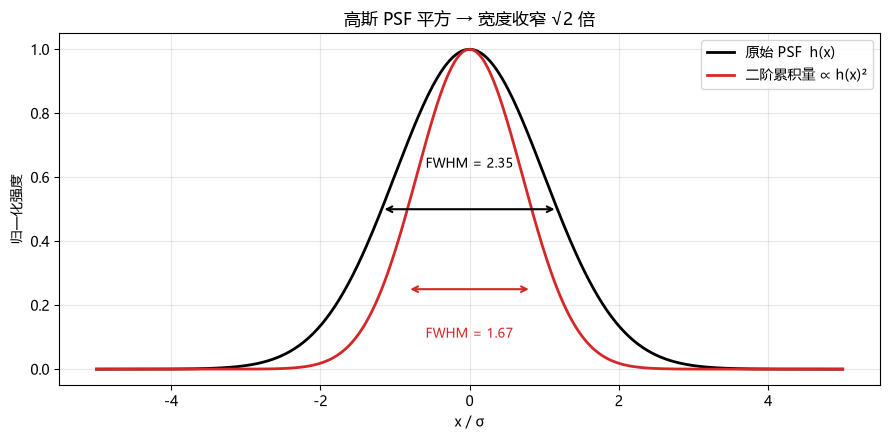

In [54]:
xs = np.linspace(-5, 5, 501)
h  = gauss_1d(xs, 0, 1.0)
h2 = h ** 2
fwhm1 = 2 * np.sqrt(2 * np.log(2))
fwhm2 = fwhm1 / np.sqrt(2)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(xs, h,  'k-',  lw=2, label='原始 PSF  h(x)')
ax.plot(xs, h2, 'C3-', lw=2, label='二阶累积量 ∝ h(x)²')
for y, c, fw, off in [(0.5, 'k', fwhm1, 0.12), (0.25, 'C3', fwhm2, -0.12)]:
    ax.annotate('', xy=(-fw / 2, y), xytext=(fw / 2, y),
                arrowprops=dict(arrowstyle='<->', color=c, lw=1.5))
    ax.text(0, y + off, f'FWHM = {fw:.2f}', ha='center',
            va='bottom' if off > 0 else 'top', color=c, fontsize=9)
ax.set_xlabel('x / σ')
ax.set_ylabel('归一化强度')
ax.set_title('高斯 PSF 平方 → 宽度收窄 √2 倍')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 四个对照组合（N_FRAMES 帧 · Poisson 光子）

每张子图：灰色虚线 = 原始时间均值（归一化）；彩色实线 = 二阶累积量（归一化到自身峰值）。
灰色点划线标出两个发射体真实位置。重点对比“闪烁 vs 无闪烁”与“0 时滞 vs 1 时滞”。

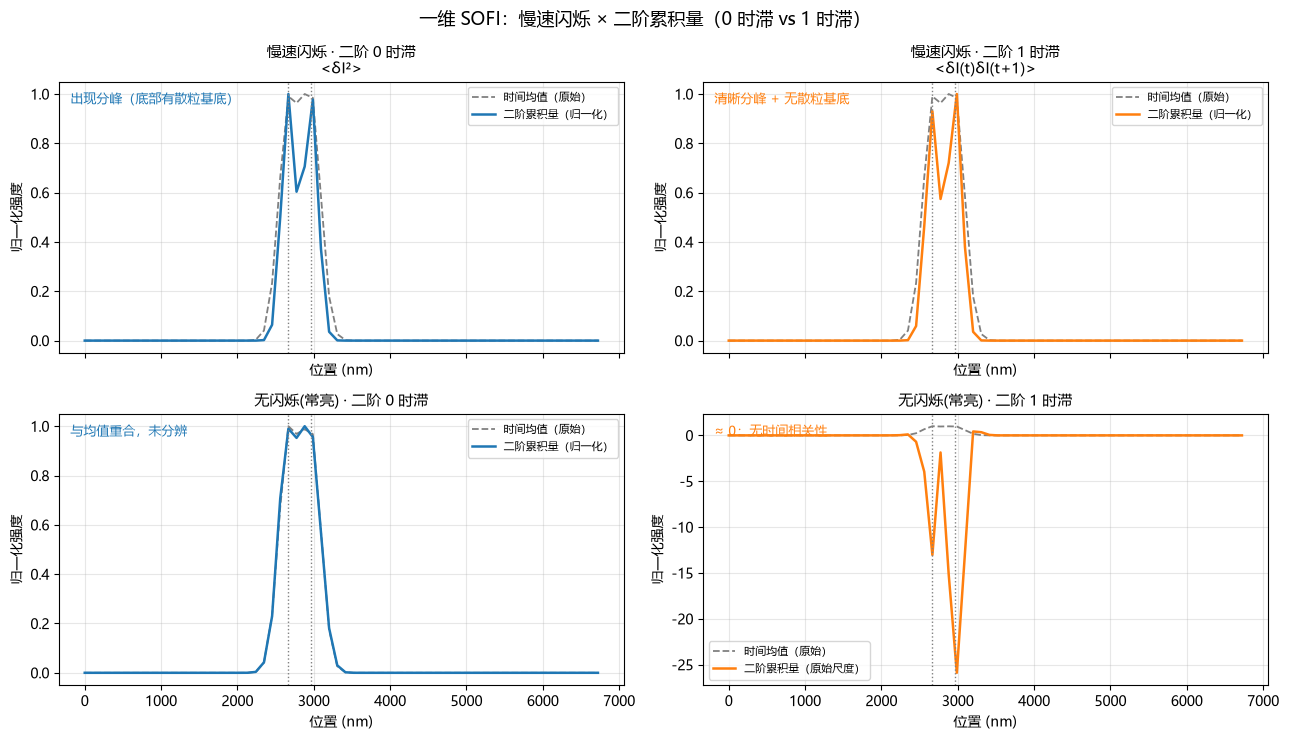

In [55]:
def normalize(y):
    m = np.abs(y).max()
    return y / m if m > 0 else y


fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
x_nm = x * PIXEL_NM
panels = [('blink', 'lag0'), ('blink', 'lag1'),
          ('static', 'lag0'), ('static', 'lag1')]
titles = {
    ('blink', 'lag0'):   '慢速闪烁 · 二阶 0 时滞\n<δI²>',
    ('blink', 'lag1'):   '慢速闪烁 · 二阶 1 时滞\n<δI(t)δI(t+1)>',
    ('static', 'lag0'):  '无闪烁(常亮) · 二阶 0 时滞',
    ('static', 'lag1'):  '无闪烁(常亮) · 二阶 1 时滞',
}
notes = {
    ('blink', 'lag0'):  '出现分峰（底部有散粒基底）',
    ('blink', 'lag1'):  '清晰分峰 + 无散粒基底',
    ('static', 'lag0'): '与均值重合，未分辨',
    ('static', 'lag1'): '≈ 0：无时间相关性',
}

for ax, (case, key) in zip(axes.ravel(), panels):
    r = res[case]
    ax.plot(x_nm, normalize(r['mean']), '--', color='gray', lw=1.3,
            label='时间均值（原始）')
    if case == 'static' and key == 'lag1':
        ax.plot(x_nm, r[key], '-', lw=1.8, color='C1',
                label='二阶累积量（原始尺度）')
    else:
        ax.plot(x_nm, normalize(r[key]), '-', lw=1.8,
                color='C0' if key == 'lag0' else 'C1',
                label='二阶累积量（归一化）')
    ax.axvline(X1 * PIXEL_NM, color='gray', ls=':', lw=1)
    ax.axvline(X2 * PIXEL_NM, color='gray', ls=':', lw=1)
    ax.text(0.02, 0.92, notes[(case, key)], transform=ax.transAxes,
            fontsize=9, color='C0' if key == 'lag0' else 'C1')
    ax.set_title(titles[(case, key)], fontsize=11)
    ax.set_xlabel('位置 (nm)')
    ax.set_ylabel('归一化强度')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.suptitle('一维 SOFI：慢速闪烁 × 二阶累积量（0 时滞 vs 1 时滞）', fontsize=13)
plt.tight_layout()
plt.show()

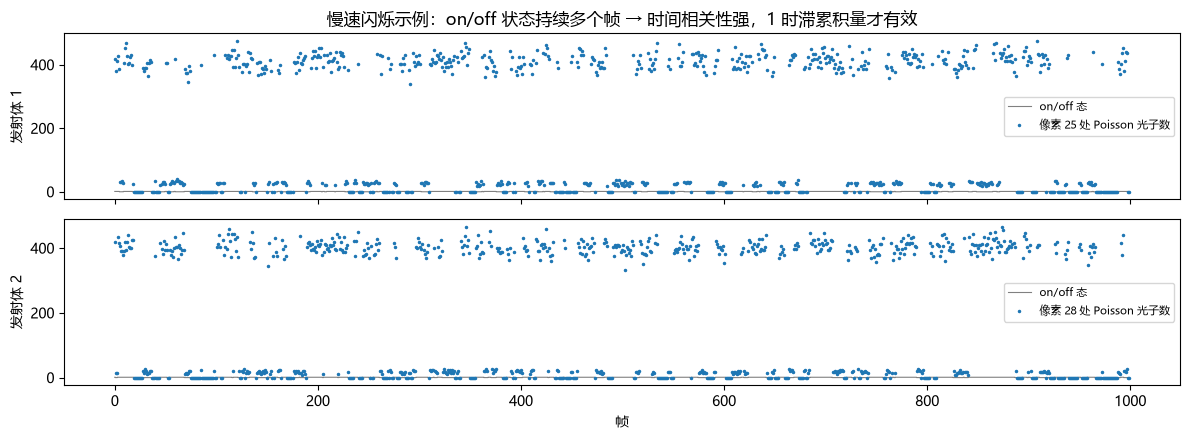

In [56]:
fig, axes = plt.subplots(2, 1, figsize=(12, 4.5), sharex=True)
for k in range(2):
    p = int(round(x0s[k]))
    axes[k].step(np.arange(N_FRAMES), res['blink']['states'][:, k],
                 where='mid', lw=0.8, color='gray', label='on/off 态')
    axes[k].plot(res['blink']['I'][:, p], '.', ms=3,
                 label=f'像素 {p} 处 Poisson 光子数')
    axes[k].set_ylabel(f'发射体 {k+1}')
    axes[k].legend(fontsize=8)
axes[-1].set_xlabel('帧')
axes[0].set_title('慢速闪烁示例：on/off 状态持续多个帧 → 时间相关性强，1 时滞累积量才有效')
plt.tight_layout()
plt.show()

In [57]:
from scipy.optimize import curve_fit

FWHM_OF_SIGMA = 2 * np.sqrt(2 * np.log(2))


def gauss_1comp(xx, amp, x0, sigma, off):
    """单高斯。"""
    return off + amp * np.exp(-0.5 * ((xx - x0) / sigma) ** 2)


def gauss_2comp(xx, a1, x1, s1, a2, x2, s2, off):
    """双高斯（用于两个发射体）。"""
    return (off + a1 * np.exp(-0.5 * ((xx - x1) / s1) ** 2)
                + a2 * np.exp(-0.5 * ((xx - x2) / s2) ** 2))


def fit_single(xx, yy, x0, win=4.0):
    """单高斯拟合，返回 (pos, sigma)。"""
    mask = np.abs(xx - x0) < win
    xs, ys = xx[mask], yy[mask]
    p0 = [ys.max(), x0, 1.0, ys.min()]
    p, _ = curve_fit(gauss_1comp, xs, ys, p0=p0, maxfev=50000)
    return p[1], p[2]


def fit_doublet(xx, yy, x0s, win=3.0):
    """发射体附近窗口内双高斯拟合，返回 [(pos, sigma), ...]；幅度塌缩则 None。"""
    mask = (xx >= min(x0s) - win) & (xx <= max(x0s) + win)
    xs, ys = xx[mask], yy[mask]
    p0 = [ys.max(), x0s[0], 0.85, ys.max(), x0s[1], 0.85, ys.min()]
    lo = [0, min(x0s) - 1.2, 0.2, 0, max(x0s) - 1.2, 0.2, -np.inf]
    hi = [np.inf, min(x0s) + 1.2, 3.0, np.inf, max(x0s) + 1.2, 3.0, np.inf]
    try:
        p, _ = curve_fit(gauss_2comp, xs, ys, p0=p0, bounds=(lo, hi), maxfev=50000)
        a1, x1, s1, a2, x2, s2, off = p
        if a1 < 0.05 * max(a1, a2) or a2 < 0.05 * max(a1, a2):
            return None
        return [(x1, s1), (x2, s2)]
    except Exception:
        return None


def dip_contrast(xx, yy, x0s):
    """两发射体之间的谷-峰对比度：1 − 谷值/峰高。"""
    i1, i2 = sorted([int(round(x0s[0])), int(round(x0s[1]))])
    peak = max(yy[i1], yy[i2])
    valley = yy[i1 + 1:i2].min()
    return 1 - valley / peak


# 原始 PSF 宽度参考：闪烁数据的时间均值（双高斯拟合还原每个发射体的真实 PSF σ）
ref_mean = fit_doublet(x, res['blink']['mean'], x0s)
s_ref = np.mean([s for _, s in ref_mean])   # ≈ 1.2 px
print(f"原始 PSF σ ≈ {s_ref:.3f} px → FWHM ≈ {s_ref * FWHM_OF_SIGMA:.2f} px\n")

print(f"{'组合':<22}{'峰位(px)':<15}{'FWHM(px)':<13}{'FWHM(nm)':<12}{'凹陷%':<7}结论")
for case in ['blink', 'static']:
    for key in ['lag0', 'lag1']:
        y = res[case][key]
        tag = case + ' + ' + key
        if case == 'static' and key == 'lag1':
            print(f"{tag:<22}{'—':<15}{'≈0':<13}{'—':<12}{'—':<7}散粒噪声，无信号")
            continue
        comps = fit_doublet(x, y, x0s)
        dc = dip_contrast(x, y, x0s)
        # “真正收窄 + 可分辨”判据：拟合位置贴近真实发射体，
        # 且拟合 σ 明显小于原始 PSF σ（阈值 0.85·σ_raw ≈ 理想 σ/√2×1.2 的余量），
        # 同时峰间存在凹陷。
        narrowed = comps is not None and all(
            abs(pos - x0) < 0.8 and s < 0.85 * s_ref
            for (pos, s), x0 in zip(comps, x0s))
        resolved = narrowed and dc > 0.08
        if comps is None:
            print(f"{tag:<22}{'—':<15}{'—':<13}{'—':<12}{dc*100:<7.0f}未分辨")
            continue
        pos_txt = " / ".join(f"{c:.1f}" for c, _ in comps)
        fws = [s * FWHM_OF_SIGMA for _, s in comps]
        fw_txt = " / ".join(f"{w:.2f}" for w in fws)
        fw_nm = " / ".join(f"{w * PIXEL_NM:.0f}" for w in fws)
        print(f"{tag:<22}{pos_txt:<15}{fw_txt:<13}{fw_nm:<12}{dc*100:<7.0f}{'分辨 ✓' if resolved else '未分辨'}")

print("\n参考：闪烁数据的时间均值（原始 PSF 形状）——单峰，凹陷仅 "
      f"{dip_contrast(x, res['blink']['mean'], x0s) * 100:.0f}%")

原始 PSF σ ≈ 1.201 px → FWHM ≈ 2.83 px

组合                    峰位(px)         FWHM(px)     FWHM(nm)    凹陷%    结论
blink + lag0          25.0 / 27.8    2.00 / 2.00  214 / 214   40     分辨 ✓
blink + lag1          25.0 / 27.8    2.00 / 2.00  214 / 214   43     分辨 ✓
static + lag0         24.8 / 27.6    2.63 / 3.07  281 / 328   4      未分辨
static + lag1         —              ≈0           —           —      散粒噪声，无信号

参考：闪烁数据的时间均值（原始 PSF 形状）——单峰，凹陷仅 3%


## 附：为什么“无闪烁(常亮) · 1 时滞”会有负值？

常亮发射体只有 Poisson 散粒噪声，帧与帧之间**独立** → 真实 1 时滞累积量严格为 **0**。
但它是从有限帧数估计出来的：估计值是**零均值、正负对称**的随机量，所以会出现负值；
其标准差 ≈ λ/√T（λ=该像素平均光子数，T=帧数）。下面用蒙特卡洛验证。

static·lag1:  mean = -1.132（≈0）, std = 4.278, |max| = 25.888
理论预测 σ ≈ λ/√T：峰值像素 λ≈426 → σ≈13.47
MC(峰像素): mean = -0.855（理论 0）, std = 13.149, 理论 λ/√T = 13.048


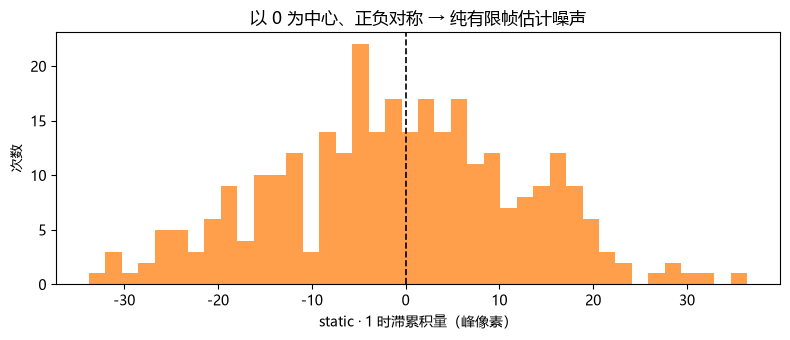

In [59]:
# 验证：无常亮(static) 的 1 时滞为什么有负值？
# 理论：帧间独立 → 真实 1 时滞累积量 = 0；有限帧估计 = 零均值噪声，正负都有，
#       标准差 ≈ λ / √T（λ = 该像素平均光子数，T = N_FRAMES）。
y_lag1 = res['static']['lag1']
lam = I_static.mean(0)
print(f"static·lag1:  mean = {y_lag1.mean():+.3f}（≈0）, "
      f"std = {y_lag1.std():.3f}, |max| = {np.abs(y_lag1).max():.3f}")
print(f"理论预测 σ ≈ λ/√T：峰值像素 λ≈{lam.max():.0f} → σ≈{lam.max()/np.sqrt(N_FRAMES):.2f}")

# 蒙特卡洛：用不同种子重复生成 static 数据，看峰像素处 1 时滞的分布
K = 300
peak = int(round(0.5 * (X1 + X2)))
lag1_pk = np.empty(K)
for k in range(K):
    I_k = simulate_1d_frames(x, x0s, states_static, BRIGHTNESS, BG,
                             np.random.default_rng(1000 + k))
    lag1_pk[k] = cumulant2_lag1(I_k)[peak]
pred_pk = lam[peak] / np.sqrt(N_FRAMES)
print(f"MC(峰像素): mean = {lag1_pk.mean():+.3f}（理论 0）, "
      f"std = {lag1_pk.std():.3f}, 理论 λ/√T = {pred_pk:.3f}")

plt.figure(figsize=(8, 3.5))
plt.hist(lag1_pk, bins=40, color='C1', alpha=0.75)
plt.axvline(0, color='k', ls='--', lw=1.2)
plt.xlabel('static · 1 时滞累积量（峰像素）')
plt.ylabel('次数')
plt.title('以 0 为中心、正负对称 → 纯有限帧估计噪声')
plt.tight_layout()
plt.show()

## 控制实验：单个发射体精确量化 FWHM 收窄倍数

上面双发射体的“原始均值”是两峰叠加的**单峰**，其 FWHM 比单高斯更宽，不适合做 √2 的定量对照。
这里用**单个**发射体（无邻近峰干扰），精确比较：原始均值 FWHM vs 慢速闪烁下 0/1 时滞累积量 FWHM。
理论预期：`FWHM_sofi ≈ FWHM_raw / √2 ≈ 0.707 × FWHM_raw`。

原始均值 FWHM      = 2.831 px = 302.1 nm
闪烁 · 0 时滞 FWHM = 2.005 px = 213.9 nm   (比值 1.412)
闪烁 · 1 时滞 FWHM = 1.985 px = 211.8 nm   (比值 1.426)
理论 √2 ≈ 1.414


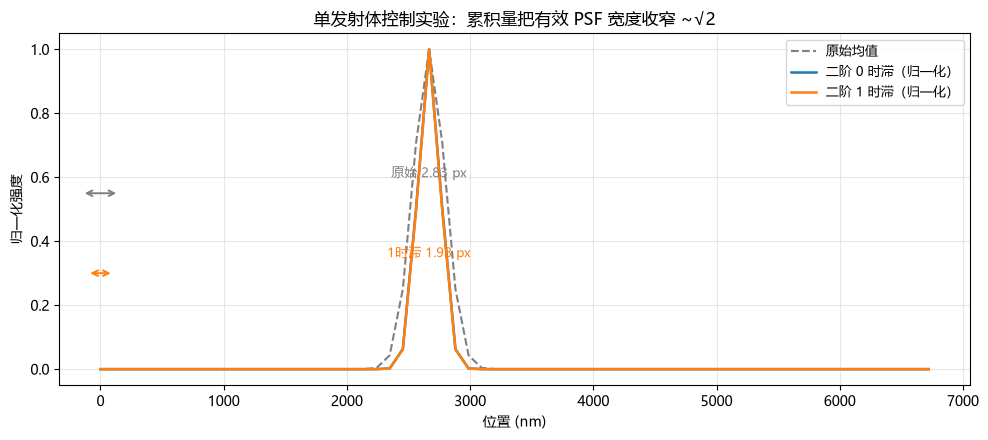

In [58]:
# 单发射体：无闪烁（测原始均值 FWHM）与 慢速闪烁（测累积量 FWHM）
I_single_static = simulate_1d_frames(x, [X1], np.ones((N_FRAMES, 1), dtype=np.int8),
                                     BRIGHTNESS, BG, rng)
st_single = markov_blink(N_FRAMES, K_ON_OFF, K_OFF_ON, rng)[:, None]
I_single_blink = simulate_1d_frames(x, [X1], st_single, BRIGHTNESS, BG, rng)

_, s_raw  = fit_single(x, I_single_static.mean(0), X1)
_, s_lag0 = fit_single(x, cumulant2_lag0(I_single_blink), X1)
_, s_lag1 = fit_single(x, cumulant2_lag1(I_single_blink), X1)
fw_raw, fw_lag0, fw_lag1 = (s * FWHM_OF_SIGMA for s in (s_raw, s_lag0, s_lag1))

print(f'原始均值 FWHM      = {fw_raw:.3f} px = {fw_raw * PIXEL_NM:.1f} nm')
print(f'闪烁 · 0 时滞 FWHM = {fw_lag0:.3f} px = {fw_lag0 * PIXEL_NM:.1f} nm   (比值 {fw_raw / fw_lag0:.3f})')
print(f'闪烁 · 1 时滞 FWHM = {fw_lag1:.3f} px = {fw_lag1 * PIXEL_NM:.1f} nm   (比值 {fw_raw / fw_lag1:.3f})')
print(f'理论 √2 ≈ {np.sqrt(2):.3f}')

# 画图
xs_nm = x * PIXEL_NM
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(xs_nm, I_single_static.mean(0) / I_single_static.mean(0).max(),
        '--', color='gray', lw=1.5, label='原始均值')
ax.plot(xs_nm, cumulant2_lag0(I_single_blink) / cumulant2_lag0(I_single_blink).max(),
        '-', lw=1.8, color='C0', label='二阶 0 时滞（归一化）')
ax.plot(xs_nm, cumulant2_lag1(I_single_blink) / cumulant2_lag1(I_single_blink).max(),
        '-', lw=1.8, color='C1', label='二阶 1 时滞（归一化）')
for y_, c_, fw_, lab in [(0.55, 'gray', fw_raw, f'原始 {fw_raw:.2f} px'),
                         (0.30, 'C1', fw_lag1, f'1时滞 {fw_lag1:.2f} px')]:
    ax.annotate('', xy=(-fw_ * PIXEL_NM / 2, y_), xytext=(fw_ * PIXEL_NM / 2, y_),
                arrowprops=dict(arrowstyle='<->', color=c_, lw=1.4))
    ax.text(X1 * PIXEL_NM, y_ + 0.05, lab, ha='center', fontsize=9, color=c_)
ax.set_xlabel('位置 (nm)')
ax.set_ylabel('归一化强度')
ax.set_title('单发射体控制实验：累积量把有效 PSF 宽度收窄 ~√2')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 结论

| 组合 | 是否收窄有效 PSF | 说明 |
|---|---|---|
| 慢速闪烁 · 1 时滞 | ✅ 最优 | 只含闪烁协方差（∝`PSF²`），散粒噪声自动消除，两峰干净分开 |
| 慢速闪烁 · 0 时滞 | ✅ 有收窄 | `PSF²` ＋ 散粒噪声基底（形状≈`PSF`），峰底有“不窄”的抬升 |
| 无闪烁 · 0 时滞 | ❌ 无收窄 | 累积量 = Poisson 方差 = 均值 ≈ 原始 `PSF`，与均值图几乎重合 |
| 无闪烁 · 1 时滞 | ❌ 无信号 | ≈ 0（帧间无相关），SOFI 无从谈起 |

**一句话**：SOFI 的“分辨率增益”来自把闪烁方差平方到 PSF 上（`h²` 收窄 √2），
而这需要发射体有**时间上相关（慢速）的闪烁**；1 时滞累积量额外把 Poisson 散粒噪声基底去掉，
所以“慢速闪烁 + 1 时滞”是效果最好、最干净的组合。